<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/03_validation_split_save.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 Validation, Split and Save
Input: furniture_v2 from Drive <br>
Output: furniture_v2_split (train/val/test) and dataset info files

In [1]:
# connect Drive and restore v2
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, matplotlib.pyplot as plt, json, shutil
from pathlib import Path

DRIVE = "/content/drive/MyDrive/DSGP"
!unzip -q -o {DRIVE}/furniture_v2.zip -d /content
final = pd.read_csv(f"{DRIVE}/furniture_v2_manifest.csv")
v1 = pd.read_csv(f"{DRIVE}/furniture_v1_manifest.csv")
print(len(final), "images in v2")

Mounted at /content/drive
3455 images in v2


In [2]:
# check every class against the rules: min 150 images and at least 30 room crops
summary = final.pivot_table(index="cls", columns="source", values="path", aggfunc="count", fill_value=0)
summary["total"] = summary.sum(axis=1)
summary["room_crops"] = final[final["room_crop"]].groupby("cls").size().reindex(summary.index, fill_value=0)
summary["min_150"] = summary["total"] >= 150
summary["room_30"] = summary["room_crops"] >= 30
summary.sort_values("total")

source,ceylon_furniture,mit_indoor,open_images_v7,total,room_crops,min_150,room_30
cls,,,,,,,
tv_stand,97,0,0,97,0,False,False
side_table,50,50,0,100,50,False,True
console_table,113,0,0,113,0,False,False
dressing_table,137,0,0,137,0,False,False
table,0,170,0,170,170,True,True
desk,18,11,150,179,161,True,True
coffee_table,22,18,150,190,168,True,True
nightstand,0,48,150,198,198,True,True
dresser,0,51,149,200,200,True,True


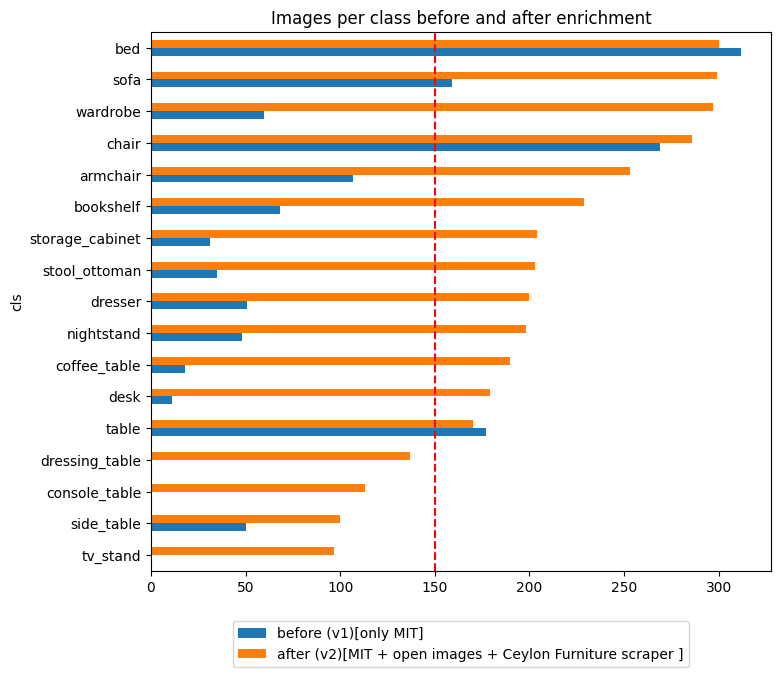

In [6]:
# before vs after: MIT only (v1) against the enriched dataset (v2)
cmp = pd.DataFrame({"before (v1)[only MIT]": v1["cls"].value_counts(),
                    "after (v2)[MIT + open images + Ceylon Furniture scraper ]": final["cls"].value_counts()}).fillna(0)
cmp.sort_values("after (v2)[MIT + open images + Ceylon Furniture scraper ]").plot(kind="barh", figsize=(8, 7))
plt.axvline(150, ls="--", color="red")
plt.title("Images per class before and after enrichment")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
plt.show()